# MAI-Image-2.6 · 02 · Edit and compose

<p align="center">
  <img src="../../.github/images/banners/mai-image-2.6.png" alt="MAI-Image-2.6: one tent, one launch kit" width="900" />
</p>

Edit pictures we already have, compose a scene from five references, ground a picture in this week's news, and get the shape right, with MAI-Image-2.6 on Microsoft Foundry.

| | |
|---|---|
| Released | 2026-08-10 (announced; generally available on Foundry by October 2026) |
| Publisher | Microsoft AI |
| Capability | [Image Generation](../../3-primers/image-generation.md) |
| Model card | [MAI-Image-2.6](https://ai.azure.com/catalog/models/MAI-Image-2.6) |
| Announcement | [Release post](https://microsoft.ai/news/mai-image-2-6-launches-at-no-2-on-arena-ahead-of-google-meta-and-xai/) |
| Docs | [Use MAI image models in Microsoft Foundry](https://learn.microsoft.com/azure/foundry/foundry-models/how-to/use-foundry-models-mai-image) |
| Deployment | Global Standard, pay-as-you-go |
| Modes | Generate from text · edit with 1–5 reference images · web grounding · auto aspect ratio |
| Picture size | Each side at least 768 px, up to 2,359,296 pixels in total (1536 × 1536) |
| Prompt | Up to 32,000 tokens, English |
| Rate limit | 6 to 36 requests a minute, by quota tier |
| Pricing | [MAI model pricing](https://aka.ms/MAIModelPricing) |
| Notebooks | [01 · Text and design](mai-image-2.6-01-text-and-design.ipynb) · **02 · Edit and compose** (this one) · faster sibling: [MAI-Image-2.6-Flash](../mai-image-2.6-flash/) |
| Env vars | `MICROSOFT_FOUNDRY_ENDPOINT` (or `MAI_IMAGE_ENDPOINT`), `AZURE_MAI_IMAGE_26_DEPLOYMENT`, `AZURE_MAI_IMAGE_26_FLASH_DEPLOYMENT`, `MAI_IMAGE_REQUESTS_PER_MINUTE`, `DEMO_MODE` |

> **Replay or live?** This notebook opens in **replay** mode (`DEMO_MODE=replay`): it shows pictures we already made and makes no Azure calls. Replay pictures are **compressed WebP copies** (up to 1024 px) to keep the repo small; a live run saves full-quality PNGs. Switch to `DEMO_MODE=live` in `.env`, or set `DEMO_MODE = "live"` in the env check cell, once the deployment is ready and you want to make your own pictures. See **Before you start** below.

**First time here?** Run [setup.ipynb](../../setup.ipynb) once to create your Microsoft Foundry project and `.env`.

> *"Can MAI-Image-2.6 fix the photos we already have, and stage a product shoot we never ran?"*

Contoso Outdoors has photos with problems, products that were never shot together, and campaigns that depend on this week's weather. We edit one photo in three steps, compose a lifestyle scene from five studio shots, try web grounding, and find the right shape for every screen. The before and after photos and the lifestyle scene became the shared [Contoso Outdoors images](../../2-scenarios/contoso-retail/) that the fal video capsules animate.

## What We Will Do

- Edit a photo in three steps and check what *didn't* change
- Compose one lifestyle scene from five reference images
- Ground a poster in live web results, and pick the right shape for banners and phone stories

> Run each cell with **Shift + Enter**. Guess first: before each picture, predict one thing it will get right and one it will get wrong.

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## Before you start

**Just reading?** Leave `DEMO_MODE=replay`. The notebook shows pictures saved in `examples/` (some point at the shared [Contoso Outdoors images](../../2-scenarios/contoso-retail/data/generated/images/)) and makes no Azure calls.

**Running it live?** We need an **MAI-Image-2.6** deployment in our Foundry project, a sign-in with a Foundry role (run `az login`; we use keyless Microsoft Entra ID tokens), and `DEMO_MODE=live` in `.env`. Our pictures go to `output/`, which git ignores, and replay shows them first from then on. Live mode never writes to the scenario folder.

In [1]:
import os
import sys
from pathlib import Path

from dotenv import load_dotenv

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "1-scripts" / "mai_image.py").exists())
load_dotenv(ROOT / ".env")

DEMO_MODE = None  # Set to "live" or "replay" to override .env
MODE = (DEMO_MODE or os.getenv("DEMO_MODE") or "replay").strip().lower()
ENDPOINT = (os.getenv("MAI_IMAGE_ENDPOINT") or os.getenv("MICROSOFT_FOUNDRY_ENDPOINT", "")).strip()
HERO = os.getenv("AZURE_MAI_IMAGE_26_DEPLOYMENT", "MAI-Image-2.6").strip()
FLASH = os.getenv("AZURE_MAI_IMAGE_26_FLASH_DEPLOYMENT", "MAI-Image-2.6-Flash").strip()
RPM = int(os.getenv("MAI_IMAGE_REQUESTS_PER_MINUTE", "6"))

if MODE not in ("replay", "live"):
    raise SystemExit(f'DEMO_MODE is "{MODE}". Use "replay" or "live".')

credential = None
if MODE == "live":
    if not ENDPOINT.startswith("https://"):
        raise SystemExit("No endpoint in .env. Set MAI_IMAGE_ENDPOINT (or MICROSOFT_FOUNDRY_ENDPOINT) to the project that has the MAI deployments.")
    from azure.identity import DefaultAzureCredential

    credential = DefaultAzureCredential()
    try:
        credential.get_token("https://cognitiveservices.azure.com/.default")
    except Exception as error:
        raise SystemExit(f"Couldn't get a Microsoft Entra token. Run `az login` in a terminal, then run this cell again.\n{error}")

print(f"Mode: {MODE} | {HERO} and {FLASH} | {RPM} requests per minute per deployment")

Mode: live | MAI-Image-2.6 and MAI-Image-2.6-Flash | 6 requests per minute per deployment


The shared helper in [1-scripts/mai_image.py](../../1-scripts/mai_image.py) sends each request with our Entra ID token, keeps to the rate limit, saves the PNG and a run log (model, seconds, size) to `output/`, and replays saved pictures. `show()` draws small thumbnails, so the notebook stays light, and links each full-size file.

In [2]:
sys.path.insert(0, str(ROOT / "1-scripts"))
from mai_image import MaiImage

HERE = ROOT / "4-models" / "mai-image-2.6"
SCENARIO = ROOT / "2-scenarios" / "contoso-retail" / "data" / "generated" / "images"
mai = MaiImage(ENDPOINT, here=HERE, mode=MODE, requests_per_minute=RPM, credential=credential)
show = mai.show

# The tent, described once, so every picture shows the same tent.
TENT = "TrailMaster X4 Tent"
LOOK = ("a four-person dome tent with a forest-green body, a burnt-orange rainfly, black mesh panels, "
        "grey reflective guylines and a small white 'OutdoorLiving' logo on the front door")

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## 1. Can it fix a photo without changing the rest?

Edits take a picture plus words. We make a campsite photo with three problems (a stranger in the background, an old price, a rainfly color we want to change) and fix one per edit, each building on the last.

> 🔮 **Guess first:** when we remove the stranger, will anything *else* change?

   e1-campsite-before: MAI-Image-2.6 | 27.9 s | 1536×1024
   e1-edit-1-remove-stranger: MAI-Image-2.6 | 18.6 s | 1248×832
   e1-edit-2-new-price: MAI-Image-2.6 | 18.5 s | 1248×832
   e1-edit-3-new-color: MAI-Image-2.6 | 17.6 s | 1248×832



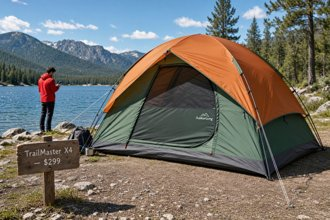
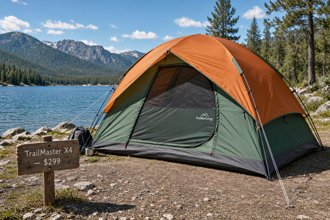
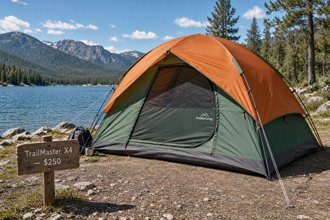
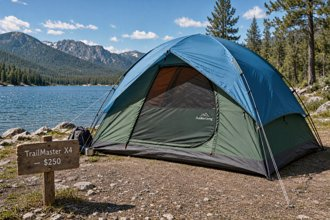

Full size: [Before](../../2-scenarios/contoso-retail/data/generated/images/campsite-before.webp) · [1 · Stranger gone](examples/e1-edit-1-remove-stranger.webp) · [2 · New price](examples/e1-edit-2-new-price.webp) · [3 · New color](../../2-scenarios/contoso-retail/data/generated/images/campsite-after.webp)


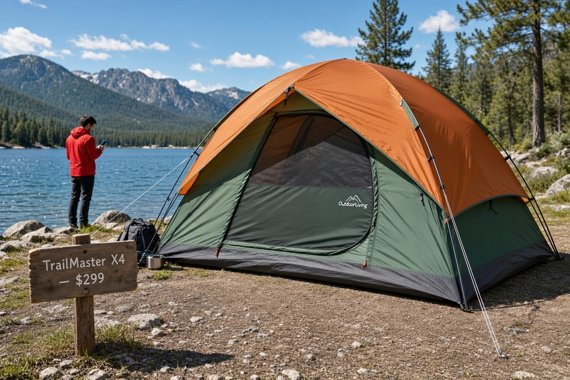
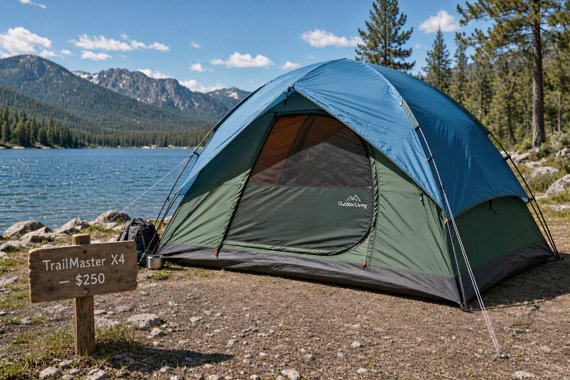

Full size: [First](../../2-scenarios/contoso-retail/data/generated/images/campsite-before.webp) · [Last](../../2-scenarios/contoso-retail/data/generated/images/campsite-after.webp)

In [3]:
CAMPSITE = f"""Photo of a lakeside campsite at midday. On the right: the {TENT}, {LOOK}.
In the background on the left, a stranger in a bright red jacket stands on the shore, looking at a phone.
In the foreground, a small wooden sign on a stake reads "TrailMaster X4 — $299"."""

campsite = mai.generate(CAMPSITE, "e1-campsite-before", HERO, size=(1536, 1024))
no_stranger = mai.edit("Remove the person in the red jacket from the background, and fill in the lake shore naturally. Change nothing else.",
                       [campsite], "e1-edit-1-remove-stranger", HERO)
new_price = mai.edit("Change the price on the wooden sign from $299 to $250. Keep the same lettering style, wood and light. Change nothing else.",
                     [no_stranger], "e1-edit-2-new-price", HERO)
new_color = mai.edit("Change the tent's rainfly from burnt orange to glacier blue. Keep the tent's shape, logo, shadows and everything else exactly the same.",
                     [new_price], "e1-edit-3-new-color", HERO)

show({"Before": campsite, "1 · Stranger gone": no_stranger, "2 · New price": new_price, "3 · New color": new_color}, height=220)
show({"First": campsite, "Last": new_color}, height=380)

**What to look for:** everything that should *not* change: the lake, the trees, the shadows, the tent's shape. Each edit is a new picture, so small details can drift a little per step; for long chains, compare the last picture with the first, as above. Note the size too: edits come back at the model's own size (1248×832 here), not the input's.

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## 2. Can five products share one scene without a photo shoot?

Edits take **up to five reference images**. We use the five studio shots from the scenario (made with [MAI-Image-2.6-Flash](../mai-image-2.6-flash/)): tent, backpack, stove, sleeping bag, and a hiker. The prompt names each one by its number. `auto_aspect_ratio` lets the model pick the shape.

> 🔮 **Guess first:** which product is most likely to lose its details?


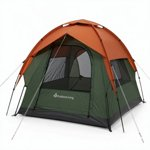
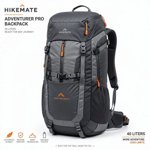
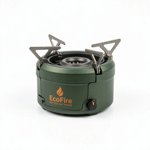
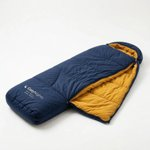
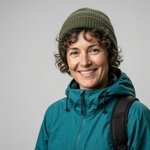

Full size: [1 · tent](../../2-scenarios/contoso-retail/data/generated/images/prop-tent.webp) · [2 · backpack](../../2-scenarios/contoso-retail/data/generated/images/prop-backpack.webp) · [3 · stove](../../2-scenarios/contoso-retail/data/generated/images/prop-stove.webp) · [4 · sleeping-bag](../../2-scenarios/contoso-retail/data/generated/images/prop-sleeping-bag.webp) · [5 · hiker](../../2-scenarios/contoso-retail/data/generated/images/prop-hiker.webp)

   e2-photoshoot: MAI-Image-2.6 | 33.6 s | 1024×1024



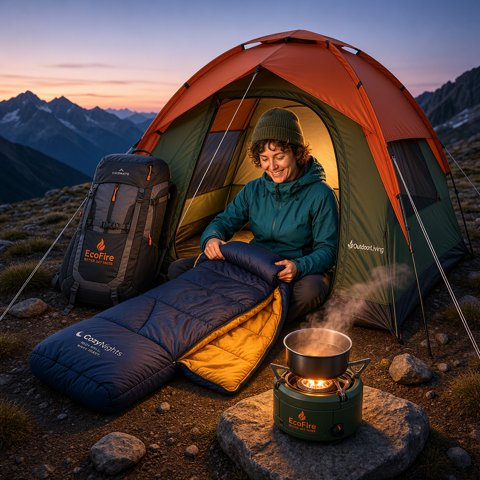

Full size: [The photoshoot that never happened](../../2-scenarios/contoso-retail/data/generated/images/lifestyle-all-products.webp)

In [4]:
PROPS = ["prop-tent", "prop-backpack", "prop-stove", "prop-sleeping-bag", "prop-hiker"]
show({f"{i} · {name[5:]}": SCENARIO / f"{name}.webp" for i, name in enumerate(PROPS, start=1)}, height=150)

PHOTOSHOOT = """One lifestyle campaign photo that uses all five reference images.
At dusk on an alpine ridge, the woman from image 5 sits in the open doorway of the tent from image 1, unrolling the sleeping bag from image 4.
The backpack from image 2 leans against the tent. The stove from image 3 burns on a flat rock in front of her, with a small pot steaming.
Keep every product's colors, logos and details exactly as in its reference. Warm lantern light, natural and unposed."""

photoshoot = mai.edit(PHOTOSHOOT, [SCENARIO / f"{name}.webp" for name in PROPS], "e2-photoshoot", HERO, auto_aspect_ratio=True)
show({"The photoshoot that never happened": photoshoot}, height=480)

**What to look for:** product by product: orange zip pulls on the pack, green base on the stove, mustard lining in the bag. Then the light: does each product match the scene? With five references, the smallest details slip first; for hero shots use fewer references and put the most important product first.

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## 3. Can a picture know about this week?

Models learn from data up to a date. With **web grounding**, MAI-Image-2.6 looks things up with Bing before it draws. We make the same store-window poster with grounding off and on, and check both against a real forecast. A replayed forecast would be out of date, so this section runs live only.

Today is Tuesday 10 November 2026. Open a weather site for Seattle to check.
   e3-window-no-grounding-20261110: MAI-Image-2.6 | 28.6 s | 1024×1280
   e3-window-grounded-20261110: MAI-Image-2.6 | 38.8 s | 1024×1280



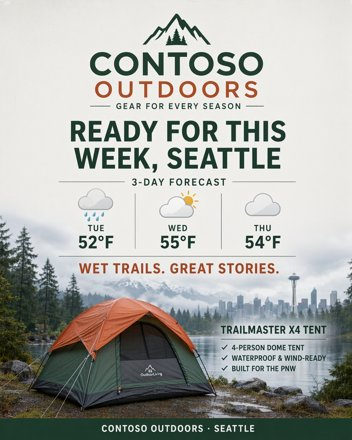
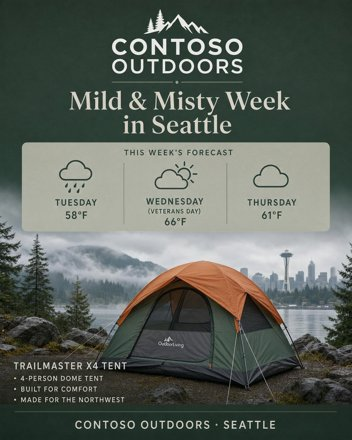

Full size: [Grounding off](examples/e3-window-no-grounding-20261110.webp) · [Grounding on](examples/e3-window-grounded-20261110.webp)

In [5]:
from datetime import date

WINDOW = f"""A store window poster for Contoso Outdoors in Seattle, Washington, for this week.
Show the real weather forecast for Seattle for the next three days: three simple weather icons, each with its day name and high temperature in °F.
Add a short headline that suits this week's weather, and the {TENT} ({LOOK}) in a matching scene.
Footer: "Contoso Outdoors · Seattle"."""

if MODE == "live":
    print(f"Today is {date.today():%A %d %B %Y}. Open a weather site for Seattle to check.")
    stamp = f"{date.today():%Y%m%d}"
    without = mai.generate(WINDOW, f"e3-window-no-grounding-{stamp}", HERO, size=(1024, 1280), web_grounding=False)
    grounded = mai.generate(WINDOW, f"e3-window-grounded-{stamp}", HERO, size=(1024, 1280), web_grounding=True)
    show({"Grounding off": without, "Grounding on": grounded}, height=440)
else:
    print("Replay mode: grounding is about *this* week, so a saved result would mislead. Set DEMO_MODE to live to try it.")

**What to look for:** the right days of the week, temperatures close to the forecast, and a headline that matches the weather. Grounding makes a picture *more likely* to be current, not guaranteed: check facts, prices, and dates before it goes live, and read how grounding handles data in the [MAI image docs](https://learn.microsoft.com/azure/foundry/foundry-models/how-to/use-foundry-models-mai-image) before using it with private information.

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## 4. Can it pick the right shape for every screen?

Two ways: `auto_aspect_ratio` lets the model **pick** a shape from the prompt; exact sizes give a website exactly 2304 × 1024. Each side must be at least 768 pixels, and the total at most 2,359,296 (1536 × 1536).

> 🔮 **Guess first:** what shape will it pick for a panorama, and for a waterfall?

   e4-auto-panorama: MAI-Image-2.6 | 35.8 s | 1536×1536
   e4-auto-waterfall: MAI-Image-2.6 | 34.8 s | 1536×1536
   e4-auto-packshot: MAI-Image-2.6 | 35.0 s | 1536×1536



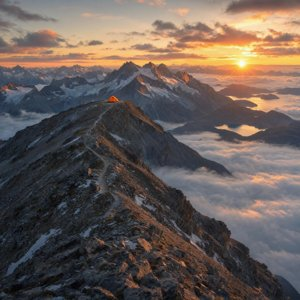
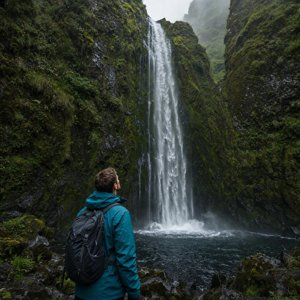
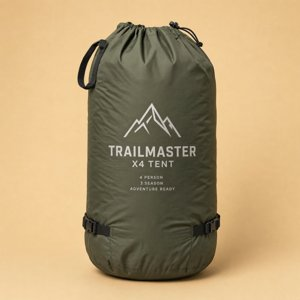

Full size: [panorama · 1536×1536](examples/e4-auto-panorama.webp) · [waterfall · 1536×1536](examples/e4-auto-waterfall.webp) · [packshot · 1536×1536](examples/e4-auto-packshot.webp)

   e4-web-banner: MAI-Image-2.6 | 37.6 s | 2304×1024
   e4-phone-story: MAI-Image-2.6 | 36.2 s | 1152×2048



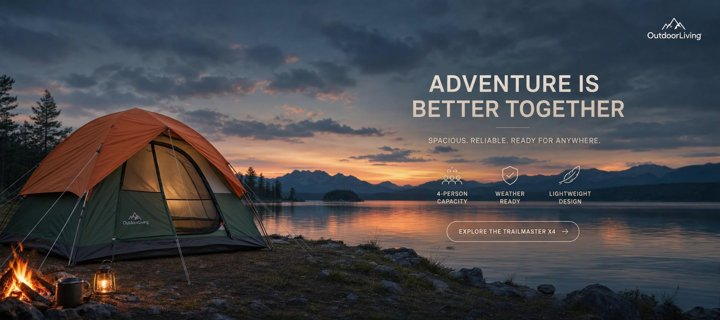
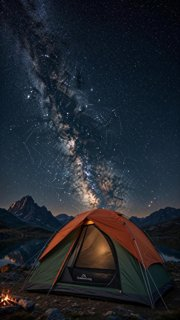

Full size: [Web banner · 2304×1024](examples/e4-web-banner.webp) · [Phone story · 1152×2048](../../2-scenarios/contoso-retail/data/generated/images/phone-story.webp)

In [6]:
SCENES = {
    "panorama": "A sweeping view of a long mountain ridge trail at sunrise, with a tiny orange tent far off on the ridgeline.",
    "waterfall": "A tall, narrow waterfall dropping down a mossy cliff, with a hiker in a teal jacket looking up from the pool below.",
    "packshot": f"The {TENT} packed in its carry bag, centered on a plain sand-colored background.",
}
framed = {}
for name, prompt in SCENES.items():
    path = mai.generate(prompt, f"e4-auto-{name}", HERO, size=None, auto_aspect_ratio=True)
    framed[f"{name} · {mai.log[f'e4-auto-{name}']['size']}"] = path
show(framed, height=300)

BANNER = f"A wide website hero banner: the {TENT} ({LOOK}) on the far left at a lakeside campsite at dusk, with calm, empty sky on the right for text."
STORY = f"A tall phone story: the {TENT} ({LOOK}) at the bottom, under a huge starry night sky and the Milky Way, with empty space at the top for a caption."
banner = mai.generate(BANNER, "e4-web-banner", HERO, size=(2304, 1024))  # 2,359,296 pixels: right at the limit
story = mai.generate(STORY, "e4-phone-story", HERO, size=(1152, 2048))
show({"Web banner · 2304×1024": banner, "Phone story · 1152×2048": story}, height=320)

**What to look for:** whether auto picked a different shape for each scene. If it picked the same one every time, that's a real result: when the shape matters, ask for an exact size. Note the phone story in the scenario folder is 900×1600: it was resized for the video models after this run.

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

### 🔧 Break it on purpose

A 1600 × 1600 picture is 2,560,000 pixels, just over the limit. Will the model shrink it, or say no?

400 from MAI-Image-2.6. The model didn't accept a setting. Check the size (each side 768 or more, 2,359,296 pixels at most), the image type (PNG or JPEG), and the options.
Model does not support request parameter value supplied: Invalid dimensions 1600x1600: total pixel count (2560000) exceeds the maximum of 2359296.
   e4-just-right: MAI-Image-2.6 | 36.1 s | 1536×1536



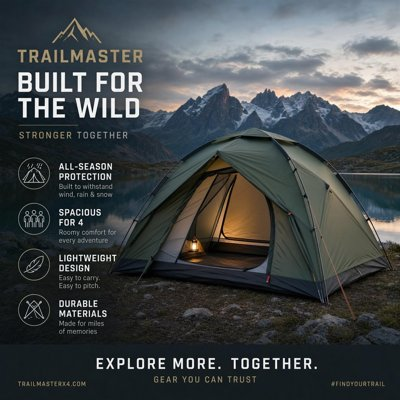

Full size: [1536×1536: right at the limit](examples/e4-just-right.webp)

In [7]:
if MODE == "live":
    try:
        mai.generate(f"A square poster of the {TENT}.", "break-too-big", HERO, size=(1600, 1600))
    except RuntimeError as error:
        print(error)
else:
    print("Replay mode: in live mode the service answers 400 and names the pixel limit. Nothing is drawn or billed.")

fits = mai.generate(f"A square poster of the {TENT}.", "e4-just-right", HERO, size=(1536, 1536))
show({"1536×1536: right at the limit": fits}, height=400)

A clear 400 beats a quiet shrink: it stops a wrong-sized banner before it ships. The message names the limit, and 1536 × 1536 fits exactly.

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## Your Turn to Explore

- **Catalog by editing.** Edit the campsite photo once per colorway from [notebook 01](mai-image-2.6-01-text-and-design.ipynb). Do edits keep the tent more consistent than one 2×2 picture?
- **Boots, not hiker.** Swap `prop-hiker` for a close-up brief of the TrekReady Hiking Boots by the tent door.
- **Grounded event.** With grounding on, ask for a poster about "the next big outdoor event in Seattle". Then check that the event is real.

In [8]:
# Your experiment here. Try: mai.edit("...", [SCENARIO / "campsite-before.webp"], "my-edit", HERO)

<img src="../../.github/images/divider.svg" alt="" width="100%" height="6" />

## What We Did

- ✅ Edited a photo in three steps and checked what didn't change
- ✅ Composed one lifestyle scene from five reference images
- ✅ Tried web grounding, and picked the right shape for banners and phone stories

➡️ **Next:** [MAI-Image-2.6-Flash](../mai-image-2.6-flash/): the same features, faster. Draft on Flash, finish on MAI-Image-2.6.

Stuck? [Open an issue](https://github.com/microsoft-foundry/model-releases/issues/new) with the failing cell's output.

**Learn more:** [Use MAI image models in Microsoft Foundry](https://learn.microsoft.com/azure/foundry/foundry-models/how-to/use-foundry-models-mai-image) · [Image Generation primer](../../3-primers/image-generation.md) · [Release post](https://microsoft.ai/news/mai-image-2-6-launches-at-no-2-on-arena-ahead-of-google-meta-and-xai/)